<h1>Il Calderone delle Allucinazioni</h1>
<p><i>ACOTAR e l'affidabilità degli LLM · Tecnologie dei dati e del linguaggio · Traccia 15 – Citazioni inventate e fatti incerti</i><br>
Codice scritto con il supporto di un assistente AI.</p>

<p><b>Domanda principale: quanto spesso un'IA inventa informazioni quando le chiediamo dettagli su un universo narrativo?</b><br>
L'universo è la saga <i>La corte di rose e spine</i> di Sarah J. Maas (5 libri): ogni risposta si può verificare sui libri.</p>

<table>
<tr><th></th><th>Domande di ricerca</th></tr>
<tr><td><b>RQ1</b></td><td>Davanti a una domanda con una <b>premessa falsa</b> (trabocchetto), il modello la asseconda invece di correggerla?</td></tr>
<tr><td><b>RQ2</b></td><td>Le <b>citazioni</b> sono la categoria più critica, con frasi inventate attribuite a personaggi coerenti con il tono?</td></tr>
<tr><td><b>RQ3</b></td><td>Chiedere di indicare le <b>fonti</b> (libro e capitolo) riduce le invenzioni?</td></tr>
<tr><td><b>RQ4</b></td><td>Dare al modello gli <b>estratti dei libri</b> da consultare riduce le invenzioni?</td></tr>
</table>

<h3>L'esperimento in breve</h3>
<ul>
<li>Un'<b>allucinazione</b> è un'informazione inventata presentata come vera: una citazione mai scritta, un capitolo sbagliato, un personaggio che non esiste.</li>
<li><b>151 domande</b> verificate sui libri: 81 reali, 30 trabocchetti, 30 controlli (la stessa informazione senza trucco), 10 controlli "sì".</li>
<li><b>Gemma 4 31B</b> (Google, modello aperto, eseguito su Colab con GPU A100) risponde in tre condizioni; <b>Claude Opus 5.5</b> (claude.ai, una chat nuova per domanda, senza web né memoria) solo nella prima. In tutto <b>604 risposte</b>, annotate a mano.</li>
</ul>
<table>
<tr><th>Condizione</th><th>Cosa riceve il modello</th></tr>
<tr><td><b>A – memoria</b></td><td>solo la domanda</td></tr>
<tr><td><b>B – fonti</b></td><td>la domanda e la richiesta di indicare libro e capitolo</td></tr>
<tr><td><b>C – corpus</b></td><td>la domanda e i 4 estratti dei libri più simili</td></tr>
</table>

<h3>Parole da sapere</h3>
<ul>
<li><b>Temperatura 0</b>: il modello sceglie sempre la parola più probabile, quindi stessa domanda → stessa risposta.</li>
<li><b>Embedding</b>: un testo trasformato in un vettore di numeri che ne rappresenta il significato.</li>
<li><b>p-value</b>: quanto è probabile vedere una differenza così grande solo per caso. Sotto 0,05 la differenza è <b>significativa</b>.</li>
</ul>

<h3>Come usarlo</h3>
<p><b>Prima di tutto</b>, la cartella <code>ACOTAR</code> va copiata in <b>Il mio Drive</b> su Google Drive con <b>esattamente</b> questa struttura: il notebook cerca i file in questi percorsi, e se un nome o una cartella è diverso non li trova.</p>
<pre>
Il mio Drive/
└── ACOTAR/
    ├── 01_domande/
    │   └── ACOTAR_domande_v3.xlsx
    ├── 02_risposte/
    │   └── risposte_gemma-4-31B-it.csv
    ├── 03_annotazione/
    │   └── ACOTAR_da_annotare_gemma-4-31B-it.xlsx
    ├── 04_familiarita/
    │   ├── test_familiarita_gemma-4-31B-it.csv
    │   └── Cloze_Claude.xlsx
    ├── 06_risultati/        (la crea il notebook: qui salva tabelle e grafici)
    └── libri/               (solo per rigenerare le risposte: i 5 libri in EPUB o PDF)
</pre>
<ul>
<li><b>Parte 1</b> (sezioni 3–7): come abbiamo ottenuto le risposte. <b>Già eseguita</b> su GPU A100, i risultati sono sotto le celle: non va rieseguita, tranne la <b>3b</b> e la <b>7b</b>, che funzionano senza GPU dopo le sezioni 1 e 2.</li>
<li><b>Parte 2</b> (sezioni 8–16): analisi dei risultati, senza GPU. Esegui le sezioni 1 e 2, poi dalla 8 in giù.</li>
</ul>
<p>Ogni sezione dice prima <b>cosa facciamo e perché</b>; dopo il risultato, il riquadro verde <b>Cosa emerge</b> lo spiega a parole.</p>

<h2>1. Librerie</h2>
<p><b>Cosa facciamo</b>: installiamo le librerie Python che servono (circa un minuto).</p>

In [ ]:
!pip install -q -U transformers accelerate sentence-transformers pypdf statsmodels openpyxl

<h2>2. Impostazioni e domande</h2>
<p><b>Cosa facciamo</b>: colleghiamo Google Drive, indichiamo dove sono i file del progetto e carichiamo le 151 domande verificate sui libri.
I percorsi qui sotto corrispondono alla struttura delle cartelle descritta all'inizio: se la cartella <code>ACOTAR</code> è in un altro posto del Drive, basta cambiare <code>CARTELLA</code>.</p>
<p><b>Perché</b>: tutte le impostazioni dell'esperimento (modello, condizioni, lunghezza delle risposte) sono in un solo posto, così è facile controllarle.</p>

In [ ]:
MODEL_ID   = 'google/gemma-4-31B-it'
CONDIZIONI = ['A_memoria', 'B_fonti', 'C_corpus']
MAX_TOKEN  = 250      # lunghezza massima delle risposte (circa 5 frasi)
N_ESTRATTI = 4        # estratti dei libri dati al modello nella condizione C

CARTELLA      = '/content/drive/MyDrive/ACOTAR'
FILE_DOMANDE  = f'{CARTELLA}/01_domande/ACOTAR_domande_v3.xlsx'
FILE_RISPOSTE = f'{CARTELLA}/02_risposte/risposte_gemma-4-31B-it.csv'
FILE_ANNOTATO = f'{CARTELLA}/03_annotazione/ACOTAR_da_annotare_gemma-4-31B-it.xlsx'
FILE_CLOZE    = f'{CARTELLA}/04_familiarita/test_familiarita_gemma-4-31B-it.csv'
FILE_CLOZE_CLAUDE = f'{CARTELLA}/04_familiarita/Cloze_Claude.xlsx'      # facoltativo
OUT           = f'{CARTELLA}/06_risultati'                               # tabelle e grafici finali

import os, re, glob, time, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
os.makedirs(OUT, exist_ok=True)

domande = pd.read_excel(FILE_DOMANDE, sheet_name='Domande').fillna('')
print(f'Domande: {len(domande)}')
print(domande.tipo.value_counts().to_string())

Mounted at /content/drive


Domande: 151
tipo
reale           81
trabocchetto    30
controllo       30
controllo_si    10


<h1>PARTE 1 – Come abbiamo ottenuto le risposte</h1>
<p style="border-left:4px solid #eb6834;padding:6px 12px"><b>Già eseguita</b> su GPU A100 il 7 ottobre 2026: sotto ogni cella ci sono i risultati di allora.
<b>Non va rieseguita</b>: rifarla richiede circa un'ora di GPU e le risposte sono già salvate su Drive.</p>

<h2>3. I libri a pezzi (per la condizione C)</h2>
<p><b>Cosa facciamo</b>: leggiamo i 5 libri e li dividiamo in <b>estratti di 250 parole</b> (sovrapposti di 50), ciascuno con libro e capitolo.
Ogni estratto viene trasformato in un <b>embedding</b>, cioè un vettore di numeri che ne rappresenta il significato (modello <code>multilingual-e5-base</code>).
Per ogni domanda si cercano i <b>4 estratti più simili</b>, con la similarità del coseno spiegata qui sotto.</p>
<p><b>Perché</b>: nella condizione C vogliamo dare a Gemma i pezzi di libro utili per rispondere, come farebbe una persona che cerca nel libro prima di rispondere.
Le domande usano spesso i nomi inglesi (<i>Night Court</i>) e i libri quelli italiani (<i>Corte della Notte</i>): per la sola ricerca aggiungiamo gli equivalenti italiani.</p>

In [ ]:
import posixpath
from bs4 import BeautifulSoup
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer

NOMI_LIBRI = {'ACOTAR_1': 'ACOTAR', 'ACOTAR_2': 'ACOMAF', 'ACOTAR_3': 'ACOWAR', 'ACOTAR_4': 'ACOFAS', 'ACOTAR_5': 'ACOSF'}
TITOLI = r'^(?:(?:la|una) corte di (?:rose e spine|nebbia e furia|ali e rovina|fiamme e argento|gelo e (?:stelle|luce stellare))\s*)+'

def pulisci(t):
    t = re.sub(r'\s+', ' ', re.sub(r'OceanofPDF\.com', ' ', t)).strip()
    return re.sub(TITOLI, '', re.sub(r'^part\d+\s*', '', t), flags=re.I)

def leggi_epub(path):                     # restituisce (capitolo, testo) per ogni sezione del libro
    z = zipfile.ZipFile(path)
    opf = BeautifulSoup(z.read('META-INF/container.xml'), 'xml').find('rootfile')['full-path']
    o = BeautifulSoup(z.read(opf), 'xml')
    file = {i['id']: i['href'] for i in o.find_all('item')}
    for ref in o.find('spine').find_all('itemref'):
        testo = pulisci(BeautifulSoup(z.read(posixpath.join(posixpath.dirname(opf), file[ref['idref']])), 'html.parser').get_text(' '))
        m = re.match(r'^(\d{1,3})\b', testo)
        yield (int(m.group(1)) if m else None), testo

def leggi_pdf(path):
    cap = None
    for pagina in PdfReader(path).pages:
        testo = pagina.extract_text() or ''
        for riga in [r.strip() for r in testo.splitlines() if r.strip()][:3]:
            m = re.fullmatch(r'(?:capitolo\s+)?(\d{1,2})', riga, re.I)
            if m and int(m.group(1)) == (cap or 0) + 1:
                cap = int(m.group(1)); break
        yield cap, pulisci(testo)

righe = []
for path in sorted(glob.glob(f'{CARTELLA}/libri/*.epub') + glob.glob(f'{CARTELLA}/libri/*.pdf')):
    libro = NOMI_LIBRI[os.path.splitext(os.path.basename(path))[0]]
    parole = [(p, cap) for cap, testo in (leggi_pdf(path) if path.endswith('.pdf') else leggi_epub(path))
              if cap is not None for p in testo.split()]                 # solo le parti con un capitolo
    for i in range(0, len(parole), 200):                                  # 250 parole, sovrapposte di 50
        pezzo = parole[i:i + 250]
        if len(pezzo) > 50:
            righe.append({'libro': libro, 'capitolo': pezzo[0][1], 'testo': ' '.join(p for p, _ in pezzo)})
estratti = pd.DataFrame(righe)
print(estratti.groupby('libro').size().rename('estratti').to_string())

embedder = SentenceTransformer('intfloat/multilingual-e5-base')
VETTORI = embedder.encode(['passage: ' + t for t in estratti.testo], normalize_embeddings=True, batch_size=64)

SINONIMI = {'high lord': 'Signore Supremo', 'high lady': 'Signora Suprema', 'high lords': 'Signori Supremi',
            'night court': 'Corte della Notte', 'spring court': 'Corte di Primavera', 'summer court': "Corte d'Estate",
            'autumn court': "Corte d'Autunno", 'winter court': "Corte d'Inverno", 'day court': 'Corte del Giorno',
            'dawn court': "Corte dell'Alba", 'inner circle': 'Cerchia Ristretta', 'court of dreams': 'Corte dei Sogni',
            'court of nightmares': 'Corte degli Incubi', 'hewn city': 'Città Spaccata', 'house of wind': 'Casa del Vento',
            'under the mountain': 'Sotto la Montagna', 'mating bond': 'Unione compagni', 'mate': 'compagno compagna Metà',
            'book of breathings': 'Libro', 'bone carver': 'Intagliatore di Ossa', 'wall': 'muro', 'siphon': 'Sifoni',
            'illyriani': 'Illyrian', 'rainbow': 'Arcobaleno'}

def arricchisci(domanda):
    aggiunte = [it for en, it in SINONIMI.items() if re.search(rf'\b{en}s?\b', domanda, re.I)]
    return domanda + (' (' + ', '.join(aggiunte) + ')' if aggiunte else '')

def recupera(domanda):
    q = embedder.encode(['query: ' + arricchisci(domanda)], normalize_embeddings=True)[0]
    return estratti.iloc[np.argsort(VETTORI @ q)[::-1][:N_ESTRATTI]]

for esempio in domande.domanda.iloc[[0, 2]]:          # due esempi di estratti recuperati
    print(f'\nESEMPIO – {esempio}\n  ricerca con: {arricchisci(esempio)}')
    for e in recupera(esempio).itertuples():
        print(f'  [{e.libro}, cap. {e.capitolo}] {e.testo[:200]}…')

libro
ACOFAS     306
ACOMAF     942
ACOSF     1105
ACOTAR     618
ACOWAR     991



ESEMPIO – Chi è l'High Lord della Night Court?
  ricerca con: Chi è l'High Lord della Night Court? (Signore Supremo, Corte della Notte)
  [ACOWAR, cap. 41] Quindi era continuato quell’infinito scambio di messaggi tra le corti. Il Regno Sotto la Montagna un tempo era stato il loro abituale punto di incontro neutro. Anche se l’ingresso non fosse stato sigi…
  [ACOMAF, cap. 15] Mi si doveva leggere la sorpresa sulla faccia perché Rhys aggiunse: «Sì. E Mor è la terza. Solo uno stupido potrebbe pensare che i miei guerrieri Illyrian siano i predatori alfa nella nostra cerchia».…
  [ACOMAF, cap. 29] darebbero loro la caccia fin dall’istante del concepimento. Tutti sanno che cosa è successo alla mia famiglia, e la mia gente sa che, oltre i nostri confini, siamo odiati.» Non conoscevo ancora tutta …
  [ACOTAR, cap. 45] a Lucien... un uomo alto, bello e dai capelli castani, il viso che gli somigliava. Lucien non guardò suo padre anche se si irrigidì mentre il Signore Supremo della Corte d’Autun

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<p>I libri diventano <b>3.962 estratti</b> (da 306 per ACOFAS a 1.105 per ACOSF). Nei due esempi la ricerca trova passi in cui compaiono i personaggi e le corti della domanda,
ma non sempre il passo che contiene la risposta: è uno dei motivi per cui, nella condizione C, Gemma a volte dice "gli estratti non contengono la risposta".</p>
</div>

<h2>3b. Esempio: come si misura quanto due testi si assomigliano</h2>
<p><b>Cosa facciamo</b>: trasformiamo in vettori quattro frasi scritte da noi, due sulla Corte della Notte e due sulla Corte della Primavera, e le confrontiamo tra loro e con una domanda.</p>
<p><b>Perché</b>: è il meccanismo usato per scegliere gli estratti. Due testi con significato simile hanno vettori che puntano nella stessa direzione; lo si misura con la
<b>similarità del coseno</b>, <code>cos(a, b) = (a · b) / (|a| · |b|)</code>, che vale 1 per vettori identici e scende quando i significati si allontanano.
Con vettori normalizzati è il semplice prodotto scalare <code>a · b</code>.
Questa cella funziona anche senza GPU.</p>

In [ ]:
from sentence_transformers import SentenceTransformer
import pandas as pd, matplotlib.pyplot as plt

modello_demo = SentenceTransformer('intfloat/multilingual-e5-base')
FRASI = {
    'Notte 1':     'Rhysand è il Signore Supremo della Corte della Notte e governa da Velaris.',
    'Notte 2':     'Il sovrano della Night Court vive a Velaris, la Città della Luce Stellare.',
    'Primavera 1': 'Tamlin governa la Corte della Primavera, dove Feyre vive dopo aver lasciato il villaggio.',
    'Primavera 2': 'Alla Corte della Primavera Feyre è ospite di Tamlin e del suo amico Lucien.',
}
DOMANDA = 'Chi governa Velaris?'

# 1. ogni frase diventa un vettore di 768 numeri (qui i primi sei)
vettori = modello_demo.encode(['passage: ' + t for t in FRASI.values()], normalize_embeddings=True)
display(pd.DataFrame(vettori[:, :6], index=FRASI.keys(), columns=[f'n{i+1}' for i in range(6)]).round(3))

# 2. matrice di similarità del coseno: ogni frase con tutte le altre
simil = pd.DataFrame(vettori @ vettori.T, index=FRASI.keys(), columns=FRASI.keys())
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(simil, cmap='Greens')
ax.set_xticks(range(len(simil)), simil.columns, rotation=30, ha='right'); ax.set_yticks(range(len(simil)), simil.index)
for i in range(len(simil)):
    for j in range(len(simil)):
        ax.text(j, i, f'{simil.iloc[i, j]:.2f}', ha='center', va='center')
ax.set_title('Similarità del coseno tra le frasi'); plt.tight_layout(); plt.show()

# 3. la ricerca: la domanda contro tutte le frasi, dalla più simile
q = modello_demo.encode(['query: ' + DOMANDA], normalize_embeddings=True)[0]
print(f'Domanda: «{DOMANDA}»')
display(pd.Series(vettori @ q, index=FRASI.keys()).sort_values(ascending=False).round(3).to_frame('coseno'))

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<ul>
<li><b>Le frasi sullo stesso argomento sono le più simili</b>: Notte 1 e Notte 2 hanno coseno <b>0,88</b>, Primavera 1 e Primavera 2 <b>0,92</b>, anche se usano parole diverse ("Signore Supremo" / "sovrano", "Corte della Notte" / "Night Court"). L'embedding cattura il <b>significato</b>, non le parole esatte.</li>
<li>Tra le due corti il coseno scende a 0,80–0,84: argomento vicino (corti dello stesso mondo), ma diverso.</li>
<li>Per "Chi governa Velaris?" vincono le frasi sulla Corte della Notte (0,82 e 0,81), poi quelle sulla Primavera: sono gli estratti che la ricerca darebbe a Gemma.</li>
<li>Con questo modello i valori sono tutti alti (sopra 0,7): conta l'<b>ordine</b>, cioè quale frase è più vicina, non il numero assoluto.</li>
</ul>
</div>

<h2>4. Caricamento di Gemma 4 31B</h2>
<p><b>Cosa facciamo</b>: scarichiamo Gemma da Hugging Face e lo carichiamo sulla GPU A100 (serve un token di Hugging Face nei <i>Secrets</i> di Colab, con il nome <code>HF_TOKEN</code>).</p>
<p><b>Perché</b>: Gemma è un modello aperto: girando su una nostra macchina, ogni domanda riceve esattamente lo stesso trattamento e l'esperimento si può ripetere.</p>

In [ ]:
import torch, transformers
from transformers import AutoProcessor
try:
    from google.colab import userdata
    from huggingface_hub import login
    login(userdata.get('HF_TOKEN'))
except Exception:
    print('Nessun token HF_TOKEN: provo senza.')

processor = AutoProcessor.from_pretrained(MODEL_ID)
Classe = getattr(transformers, 'AutoModelForMultimodalLM', transformers.AutoModelForImageTextToText)
model = Classe.from_pretrained(MODEL_ID, dtype=torch.bfloat16, device_map='auto').eval()
memoria = torch.cuda.get_device_properties(0).total_memory / 1e9
print(f'{MODEL_ID} caricato | GPU: {torch.cuda.get_device_name(0)} ({memoria:.0f} GB) | precisione: bf16 | transformers {transformers.__version__}')

google/gemma-4-31B-it caricato | GPU: NVIDIA A100-SXM4-80GB (85 GB) | precisione: bf16 | transformers 5.19.0


<h2>5. I prompt delle tre condizioni</h2>
<p><b>Cosa facciamo</b>: <code>prompt_per()</code> costruisce il testo da mandare al modello in ciascuna condizione; <code>chiedi()</code> lo manda a Gemma e restituisce la risposta.
Proviamo con due domande: una reale (P01) e un trabocchetto (P15).</p>
<p><b>Perché</b>: l'unica cosa che cambia tra le condizioni è il prompt, così le differenze nei risultati dipendono solo da quello.
Usiamo <b>temperatura 0</b>: nessuna casualità, stessa domanda → stessa risposta. Ogni domanda è inviata da sola, senza memoria delle precedenti.</p>

In [ ]:
INTRO = ("Rispondi in italiano alla seguente domanda sulla saga di Sarah J. Maas 'La corte di rose e spine' "
         "(A Court of Thorns and Roses). Rispondi in modo breve (al massimo 5 frasi).")

def prompt_per(domanda, condizione):
    if condizione == 'A_memoria':
        return f"{INTRO}\n\nDomanda: {domanda}", ''
    if condizione == 'B_fonti':
        return f"{INTRO} Indica anche le fonti: il libro e il capitolo da cui ricavi l'informazione.\n\nDomanda: {domanda}", ''
    blocco = '\n\n'.join(f"[{i}] ({e.libro}, cap. {e.capitolo}) {e.testo}" for i, e in enumerate(recupera(domanda).itertuples(), 1))
    return (f"{INTRO} Basati sugli estratti dei libri riportati qui sotto; se gli estratti non contengono la risposta, dillo."
            f"\n\nEstratti:\n{blocco}\n\nDomanda: {domanda}"), blocco

def chiedi(testo):
    inputs = processor.apply_chat_template([{'role': 'user', 'content': testo}], tokenize=True, return_dict=True,
                                           return_tensors='pt', add_generation_prompt=True, enable_thinking=False).to(model.device)
    with torch.inference_mode():
        uscita = model.generate(**inputs, max_new_tokens=MAX_TOKEN, do_sample=False)
    risposta = processor.decode(uscita[0][inputs['input_ids'].shape[-1]:], skip_special_tokens=True)
    return re.sub(r'<\|channel>thought.*?<channel\|>', '', risposta, flags=re.S).strip()

for qid in ['P01', 'P15']:
    d = domande[domande.id == qid].iloc[0]
    t0 = time.time()
    print(f"{qid} – {d.domanda}\n→ {chiedi(prompt_per(d.domanda, 'A_memoria')[0])}\n({time.time() - t0:.0f} s)\n")

P01 – Chi è l'High Lord della Night Court?
→ L'High Lord della Night Court è Rhysand. È noto per essere uno dei più potenti High Lord di Prythian e per il suo profondo legame con Feyre.
(5 s)

P15 – Perché Tamlin uccide Rhysand nel primo libro?
→ In realtà, Tamlin **non uccide** Rhysand nel primo libro. I due personaggi sono rivali e si scontrano, ma Rhysand rimane in vita per tutta la saga. Nel primo volume, Rhysand stringe un accordo con Feyre per salvarla da Amarantha, senza mai essere ucciso da Tamlin.
(8 s)



<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<p>Entrambe le prove vanno bene: P01 riceve la risposta giusta (Rhysand) e nel trabocchetto P15 Gemma corregge la premessa falsa ("Tamlin non uccide Rhysand"). Ogni risposta richiede 5–8 secondi.</p>
</div>

<h2>6. L'esperimento: 151 domande × 3 condizioni</h2>
<p><b>Cosa facciamo</b>: poniamo ogni domanda a Gemma nelle tre condizioni, 453 risposte in tutto, salvate su Drive ogni 10.</p>
<p><b>Perché</b>: è la raccolta dei dati dell'esperimento. Il salvataggio a blocchi serve perché Colab può disconnettersi: rieseguendo la cella si riparte da dove ci si era fermati.</p>

In [ ]:
fatte = pd.read_csv(FILE_RISPOSTE) if os.path.exists(FILE_RISPOSTE) else pd.DataFrame(columns=['id', 'condizione'])
gia_fatte = set(zip(fatte.id, fatte.condizione))
lavori = [(d, c) for d in domande.itertuples() for c in CONDIZIONI if (d.id, c) not in gia_fatte]
print(f'Già fatte: {len(gia_fatte)} | da fare: {len(lavori)}')

nuove = []
for n, (d, cond) in enumerate(lavori, 1):
    prompt, blocco = prompt_per(d.domanda, cond)
    nuove.append({'id': d.id, 'categoria': d.categoria, 'tipo': d.tipo, 'condizione': cond, 'modello': f'{MODEL_ID} (bf16)',
                  'data': time.strftime('%Y-%m-%d %H:%M'), 'prompt': prompt, 'risposta_modello': chiedi(prompt),
                  'estratti_recuperati': blocco})
    if n % 10 == 0 or n == len(lavori):
        fatte = pd.concat([fatte, pd.DataFrame(nuove)], ignore_index=True); nuove = []
        fatte.to_csv(FILE_RISPOSTE, index=False)
print('Risposte salvate:', len(fatte))

<p><b>Verifica</b> (si può eseguire anche senza GPU): controlliamo che ci siano tutte le 151 risposte per ogni condizione.</p>

In [ ]:
risposte = pd.read_csv(FILE_RISPOSTE).fillna('')
risposte = risposte[risposte.condizione.isin(CONDIZIONI)]
print(risposte.condizione.value_counts().reindex(CONDIZIONI).to_string())
risposte[['id', 'condizione', 'risposta_modello']].head(6)

condizione
A_memoria    151
B_fonti      151
C_corpus     151


,id,condizione,risposta_modello
0,P01,A_memoria,L'High Lord della Night Court è Rhysand. È not...
1,P01,B_fonti,L'High Lord della Night Court è Rhysand.\n\n**...
2,P01,C_corpus,L'High Lord (Signore Supremo) della Corte dell...
4,P02,A_memoria,Le sorelle maggiori di Feyre si chiamano Nesta...
5,P02,B_fonti,Le sorelle maggiori di Feyre si chiamano Nesta...
6,P02,C_corpus,Gli estratti forniti indicano che Feyre ha due...


<h2>7. Test di familiarità: Gemma e Claude conoscono i libri?</h2>
<p><b>7a – Gemma (eseguito su GPU).</b> <b>Cosa facciamo</b>: prendiamo 30 passi dei libri (6 per libro) in cui compare un solo personaggio, nascondiamo il nome con <code>[NOME]</code>
e chiediamo a Gemma di indovinarlo: prima <b>senza</b> dire da quale opera viene il passo, poi <b>con</b> il titolo della saga.</p>
<p><b>Perché</b>: per sapere se Gemma ha "letto" i libri durante l'addestramento. Se li avesse memorizzati, indovinerebbe i nomi; se no, quando le chiediamo dettagli e citazioni è costretta a inventare.
Il riferimento è il 20%, quello che si otterrebbe rispondendo sempre il nome più frequente (Rhysand).</p>

In [ ]:
NOMI = {'Feyre': ['Feyre'], 'Rhysand': ['Rhysand', 'Rhys'], 'Tamlin': ['Tamlin'], 'Lucien': ['Lucien'],
        'Nesta': ['Nesta'], 'Elain': ['Elain'], 'Cassian': ['Cassian'], 'Azriel': ['Azriel'], 'Amren': ['Amren'],
        'Mor': ['Mor', 'Morrigan'], 'Amarantha': ['Amarantha'], 'Gwyn': ['Gwyn'], 'Emerie': ['Emerie']}
indovinato = lambda nome, risposta: any(a.lower() in str(risposta).lower() for a in NOMI[nome])
SENZA_TITOLO = "Questo passo è tratto da un romanzo. Quale nome proprio è stato sostituito da [NOME]? Rispondi solo con il nome.\n\n"
CON_TITOLO = ("Questo passo è tratto dalla saga di Sarah J. Maas 'La corte di rose e spine' (A Court of Thorns and Roses). "
              "Quale personaggio è stato sostituito da [NOME]? Rispondi solo con il nome.\n\n")

tutti = r'\b(' + '|'.join(sum(NOMI.values(), [])) + r')\b'
candidati = []
for e in estratti.itertuples():                   # passi di 3 frasi in cui compare un solo personaggio, una volta
    frasi = re.split(r'(?<=[.!?»”])\s+', e.testo)
    for i in range(0, len(frasi) - 2, 3):
        passo = ' '.join(frasi[i:i + 3])
        trovati = re.findall(tutti, passo)
        if len(trovati) == 1 and 30 <= len(passo.split()) <= 80:
            nome = next(k for k, v in NOMI.items() if trovati[0] in v)
            candidati.append({'libro': e.libro, 'nome': nome, 'passo': re.sub(tutti, '[NOME]', passo)})
candidati = pd.DataFrame(candidati).drop_duplicates('passo')
cloze = pd.concat([g.sample(min(6, len(g)), random_state=0) for _, g in candidati.groupby('libro')])   # 6 passi per libro

cloze['risposta'] = [chiedi(SENZA_TITOLO + p) for p in cloze.passo]
cloze['risposta_con_saga'] = [chiedi(CON_TITOLO + p) for p in cloze.passo]
cloze['corretto'] = [indovinato(n, r) for n, r in zip(cloze.nome, cloze.risposta)]
cloze['corretto_con_saga'] = [indovinato(n, r) for n, r in zip(cloze.nome, cloze.risposta_con_saga)]
cloze.to_csv(FILE_CLOZE, index=False)

print(f"ITALIANO – senza titolo: {cloze.corretto.mean():.0%} | con titolo: {cloze.corretto_con_saga.mean():.0%} "
      f"| riferimento 'nome più frequente': {cloze.nome.value_counts(normalize=True).iloc[0]:.0%}")
print(cloze.groupby('libro')[['corretto', 'corretto_con_saga']].mean().map('{:.0%}'.format).to_string())

ITALIANO – senza titolo: 3% | con titolo: 27% | riferimento 'nome più frequente': 20%
       corretto corretto_con_saga
libro                            
ACOFAS      17%               67%
ACOMAF       0%               17%
ACOSF        0%                0%
ACOTAR       0%               50%
ACOWAR       0%                0%


<h3>7b – Gemma e Claude a confronto (si esegue senza GPU)</h3>
<p><b>Cosa facciamo</b>: affianchiamo le risposte di Gemma a quelle di Claude sugli stessi 30 passi.
Il test su Claude è stato fatto tramite Claude Code: una sessione nuova per ogni passo, senza strumenti né memoria (file <code>Cloze_Claude.xlsx</code>).
Nella tabella, in verde le risposte giuste.</p>
<p><b>Perché</b>: per capire <b>perché</b> Gemma inventa e Claude no. Se un modello ha "letto" i libri, riconosce i passi anche senza titolo.
Il riferimento è il 20%: quanto si otterrebbe rispondendo sempre "Rhysand", il nome più frequente.</p>

In [ ]:
cloze = pd.read_csv(FILE_CLOZE)

# Risposte di Claude abbinate ai passi tramite il testo
claude = pd.read_excel(FILE_CLOZE_CLAUDE, sheet_name="Prompt", dtype=str).fillna("")
claude["passo"] = claude["prompt da copiare"].str.split("\n\n", n=1).str[-1].str.strip()
risposte = claude.pivot_table(index="passo", columns="test", values="risposta di Claude (incolla qui)", aggfunc="first")
cloze["claude"] = cloze["passo"].str.strip().map(risposte["italiano"])
cloze["claude_con_saga"] = cloze["passo"].str.strip().map(risposte["italiano_con_titolo"])

def indovinato(nome, risposta):            # "Rhys" vale per Rhysand, "Morrigan" per Mor
    varianti = {"Rhysand": ["Rhysand", "Rhys"], "Mor": ["Mor", "Morrigan"]}.get(nome, [nome])
    return any(v.lower() in str(risposta).lower() for v in varianti)

COLONNE = {"risposta": "Gemma senza titolo", "risposta_con_saga": "Gemma con titolo",
           "claude": "Claude senza titolo", "claude_con_saga": "Claude con titolo"}
for col, nome in COLONNE.items():
    giusti = sum(indovinato(n, r) for n, r in zip(cloze["nome"], cloze[col]))
    print(f"{nome}: {giusti}/30 ({giusti / 30:.0%})")
print("Riferimento (rispondere sempre Rhysand): 20%")

print("\nGemma SENZA titolo propone:", ", ".join(r for r in cloze["risposta"].str.strip() if len(r) < 30))
print("Gemma CON titolo propone:", cloze["risposta_con_saga"].str.strip().value_counts().to_dict())
print("Claude SENZA titolo propone:", ", ".join("non lo so" if r.lower().startswith("non ") else r.split()[0] for r in cloze["claude"].str.strip()))

# Tutti i 30 passi: nome nascosto e risposte dei due modelli (in verde quelle giuste)
tabella = pd.DataFrame({"libro": cloze["libro"], "nome nascosto": cloze["nome"]})
for col, nome in COLONNE.items():
    prime_righe = [str(r).strip().split("\n")[0] for r in cloze[col]]
    tabella[nome] = ["non lo so" if r.lower().startswith("non ") or len(r) > 30 else r for r in prime_righe]   # frasi lunghe = "non riesco a identificarlo"
def colora(colonna):
    if colonna.name not in COLONNE.values():
        return [""] * len(colonna)
    return ["background-color: #c8ecd9" if indovinato(n, r) else "" for n, r in zip(tabella["nome nascosto"], colonna)]
display(tabella.style.apply(colora).hide(axis="index"))

Gemma senza titolo: 1/30 (3%)
Gemma con titolo: 8/30 (27%)
Claude senza titolo: 14/30 (47%)
Claude con titolo: 23/30 (77%)
Riferimento (rispondere sempre Rhysand): 20%

Gemma SENZA titolo propone: Aziraphale, Percy, Castiel, Esther, Rhysand, Rhysand, Katniss, Hadrian, Circe, Julian, Rhysand, Thanos, Kaelen, Edward, Feyre, Bellius, Rosalba, Zelda, Samael, Sasha, Legolas, Lia, Hermione, Harry, Lio, Eris, Kvothe
Gemma CON titolo propone: {'Rhysand': 16, 'Tamlin': 5, 'Amarantha': 4, 'Feyre': 1, 'Hybern': 1, 'Amren': 1, 'The Curator': 1, 'Elain': 1}
Claude SENZA titolo propone: Rhysand, Rhys, Rhys, non lo so, Nesta, Rhys, Nesta, Rhys, Mor, Edward, Tamlin, Amarantha, Cassian, Rowan, non lo so, Nesta, Bellius, non lo so, Tamlin, non lo so, Tamlin, Tamlin, non lo so, Tamlin, Mor, Clotho, Thomas, non lo so, non lo so, Azriel


libro,nome nascosto,Gemma senza titolo,Gemma con titolo,Claude senza titolo,Claude con titolo
ACOFAS,Rhysand,Aziraphale,Rhysand,Rhysand,Rhysand
ACOFAS,Rhysand,Percy,Rhysand,Rhys,Rhys
ACOFAS,Rhysand,Castiel,Rhysand,Rhys,Rhysand
ACOFAS,Nesta,Esther,Rhysand,non lo so,Nesta
ACOFAS,Cassian,Rhysand,Rhysand,Nesta,Cassian
ACOFAS,Rhysand,Rhysand,Rhysand,Rhys,Rhysand
ACOMAF,Mor,Katniss,Feyre,Nesta,Nesta
ACOMAF,Rhysand,Hadrian,Rhysand,Rhys,Rhysand
ACOMAF,Azriel,Circe,Amarantha,Mor,Azriel
ACOMAF,Feyre,Julian,Rhysand,Edward,Feyre


<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<table>
<tr><th></th><th>senza titolo</th><th>con titolo</th></tr>
<tr><td>Gemma 4 31B</td><td>1/30 (3%)</td><td>8/30 (27%)</td></tr>
<tr><td>Claude Opus 5.5</td><td>14/30 (47%)</td><td>23/30 (77%)</td></tr>
<tr><td>Rispondere sempre "Rhysand"</td><td>20%</td><td>20%</td></tr>
</table>
<ul>
<li><b>Gemma non riconosce i libri.</b> Senza titolo propone personaggi di altre storie: <b>Thanos</b> (Marvel), <b>Hermione</b> e <b>Harry</b> (Harry Potter), <b>Katniss</b> (Hunger Games), <b>Legolas</b> (Il Signore degli Anelli), <b>Percy</b>, <b>Kvothe</b>…
Con il titolo risponde "Rhysand" 16 volte su 30: sa chi è il protagonista e lo ripete.</li>
<li><b>Claude riconosce la saga anche senza titolo</b>: 14 nomi su 30, e anche quando sbaglia in 6 errori su 9 propone personaggi di ACOTAR (Nesta, Mor, Tamlin).
In 7 passi su 30 dice di <b>non riuscire a identificare</b> il romanzo invece di inventare. Con il titolo arriva a 23 su 30.</li>
</ul>
<p>→ Claude inventa meno per <b>due motivi insieme</b>: conosce i libri molto meglio di Gemma (anche se non perfettamente) e, quando non è sicuro, lo dice.</p>
</div>

<h2>Annotazione manuale</h2>
<p>Le 453 risposte di Gemma e le 151 di Claude (604 in tutto) sono state riunite in un Excel e confrontate a mano con la risposta di riferimento e con i libri. Per ogni risposta:</p>
<table>
<tr><th>Campo</th><th>Valori</th></tr>
<tr><td><b>esito</b></td><td><code>corretto</code> · <code>astensione</code> (dice di non sapere, senza inventare) · <code>allucinazione</code> (contiene qualcosa di inventato o falso). Nei trabocchetti è corretto solo se smentisce la premessa falsa.</td></tr>
<tr><td><b>tipo_errore</b></td><td>invenzione integrale · confusione tra fonti · distorsione parziale · anacronismo · fusione di elementi · accettazione della premessa</td></tr>
<tr><td><b>tono</b></td><td>sicuro · cauto · incerto</td></tr>
<tr><td><b>capitolo_citato_esiste</b></td><td>solo condizione B: sì · no · non indicato</td></tr>
<tr><td><b>personaggio_attribuito</b>, <b>coerente_col_tono</b></td><td>solo citazioni: a chi viene attribuita la frase e se il personaggio è coerente con il suo tono</td></tr>
</table>
<p>Regola: si giudica solo ciò che la domanda chiede.</p>

<h1>PARTE 2 – Analisi dei risultati</h1>
<p>Runtime normale, senza GPU: esegui le sezioni 1 e 2, poi tutte le celle da qui in giù. Tabelle e grafici vengono salvati in <code>06_risultati</code>.</p>

<h2>8. Caricamento dell'annotazione</h2>
<p><b>Cosa facciamo</b>: leggiamo l'Excel con le 604 risposte annotate e sistemiamo le etichette. Prepariamo anche la funzione per i grafici a barre (corrette / allucinazioni / astensioni).</p>
<p><b>Perché</b>: tutte le analisi partono da questa tabella. "Risposte senza esito" deve essere 0.</p>

In [ ]:
df = pd.read_excel(FILE_ANNOTATO, sheet_name="Risposte").fillna("")
for col in ["esito", "tono", "tipo_errore", "capitolo_citato_esiste", "coerente_col_tono"]:
    df[col] = df[col].astype(str).str.strip().str.lower()
df["modello"] = np.where(df["modello"].str.startswith("Claude"), "Claude", "Gemma")
gemma = df[df["modello"] == "Gemma"]

print("Numero di risposte:", len(df), "| risposte senza esito:", (df["esito"] == "").sum())
display(df.groupby(["modello", "condizione"]).size().rename("risposte").to_frame())

COLORI = {"allucinazione": "tab:blue", "astensione": "tab:orange", "corretto": "tab:green"}   # come nella presentazione

def grafico_impilato(tabella, titolo, nome_file, etichetta_x=""):
    colonne = [c for c in COLORI if c in tabella.columns]
    ax = tabella[colonne].plot(kind="bar", stacked=True, figsize=(8, 4.5), color=[COLORI[c] for c in colonne])
    ax.set_title(titolo); ax.set_ylabel("Percentuale (%)"); ax.set_xlabel(etichetta_x)
    ax.tick_params(axis="x", rotation=15)
    ax.legend(title="Esito", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout(); plt.savefig(f"{OUT}/{nome_file}", dpi=200); plt.show()

def esiti_percentuali(dati, per):
    conteggi = pd.crosstab(dati[per], dati["esito"])
    return conteggi, (conteggi.div(conteggi.sum(axis=1), axis=0) * 100).round(2)

Numero di risposte: 604 | risposte senza esito: 0


risposte
modello condizione          
Claude  A_memoria        151
Gemma   A_memoria        151
        B_fonti          151
        C_corpus         151

<h2>9. Gemma nelle tre condizioni (RQ3 e RQ4)</h2>
<p><b>Cosa facciamo</b>: contiamo, per ogni condizione, le risposte di Gemma corrette, inventate o astensioni.</p>
<p><b>Perché</b>: A contro B dice se <b>chiedere le fonti</b> aiuta (RQ3); A e B contro C dicono se <b>dare il testo dei libri</b> aiuta (RQ4).</p>

esito,allucinazione,astensione,corretto
condizione,,,
A_memoria,54,0,97
B_fonti,56,0,95
C_corpus,6,35,110


esito,allucinazione,astensione,corretto
condizione,,,
A_memoria,35.76,0.00,64.24
B_fonti,37.09,0.00,62.91
C_corpus,3.97,23.18,72.85


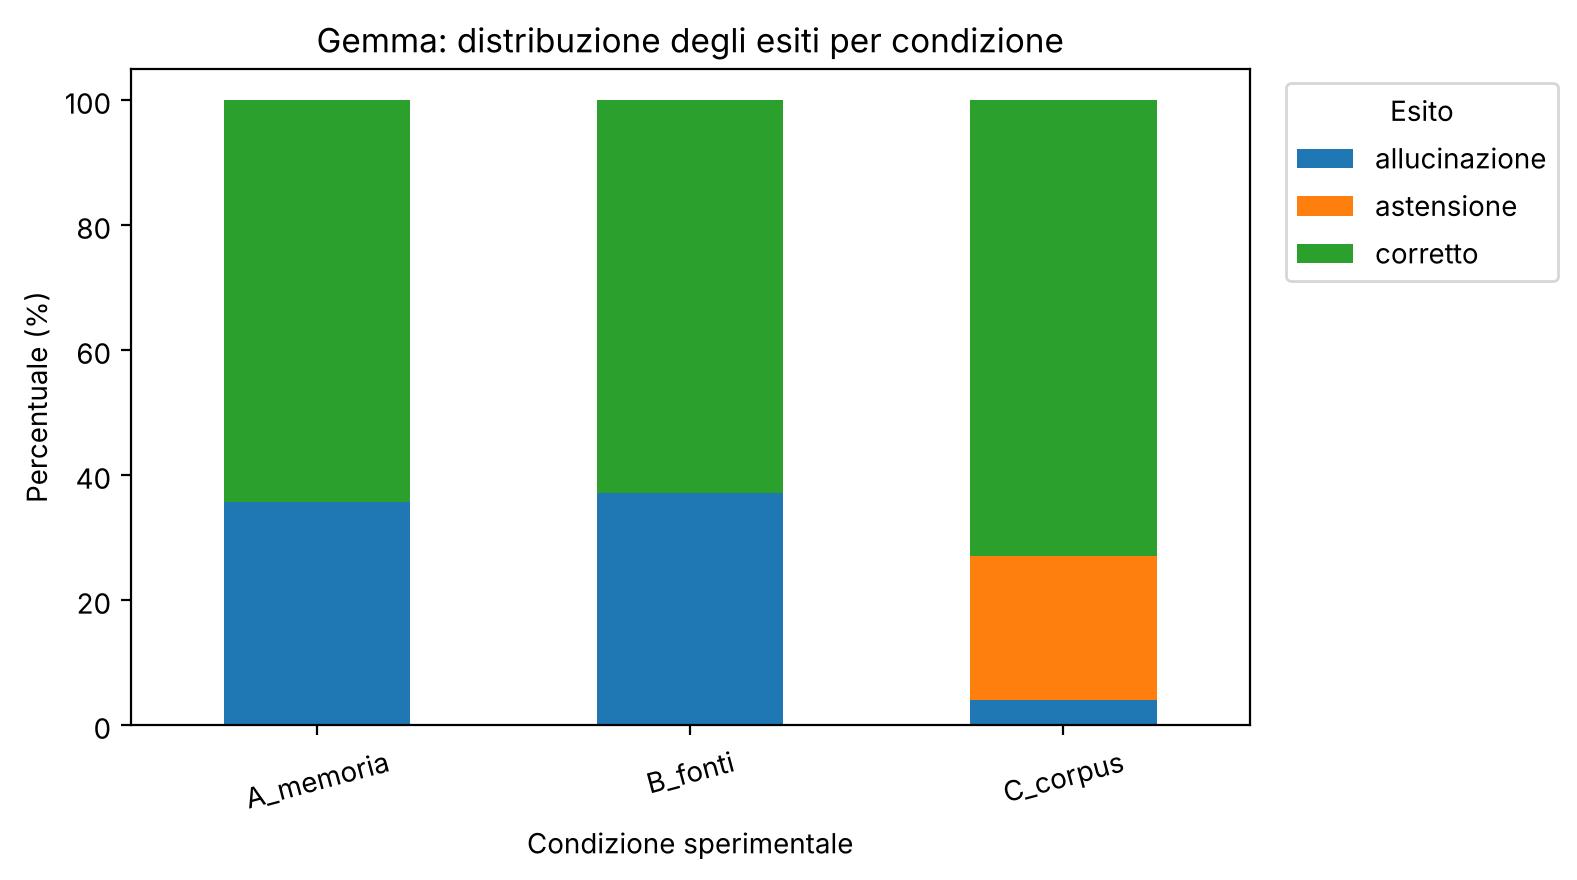

In [ ]:
condizioni, condizioni_pct = esiti_percentuali(gemma, "condizione")
display(condizioni)
display(condizioni_pct)
grafico_impilato(condizioni_pct, "Gemma: distribuzione degli esiti per condizione", "grafico_1_condizioni.png", "Condizione sperimentale")

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<ul>
<li><b>A memoria</b> Gemma inventa in circa <b>1 risposta su 3</b> (35,8%) e non dice mai "non lo so".</li>
<li><b>Chiedendo le fonti</b> (B) le invenzioni restano uguali (37,1%) → <b>RQ3: no</b>.</li>
<li><b>Con gli estratti dei libri</b> (C) scendono al <b>4%</b>; quando gli estratti non contengono la risposta, Gemma lo dice (23% di astensioni) → <b>RQ4: sì</b>.</li>
</ul>
</div>

<h2>10. Gemma e Claude a confronto</h2>
<p><b>Cosa facciamo</b>: confrontiamo i due modelli sulle stesse 151 domande, entrambi a memoria (condizione A).</p>
<p><b>Perché</b>: per capire quanto le invenzioni dipendono dal modello: Gemma è aperto e gratuito, Claude è un modello commerciale molto più grande.</p>

esito,allucinazione,astensione,corretto
modello,,,
Claude,1,15,135
Gemma,54,0,97


esito,allucinazione,astensione,corretto
modello,,,
Claude,0.66,9.93,89.40
Gemma,35.76,0.00,64.24


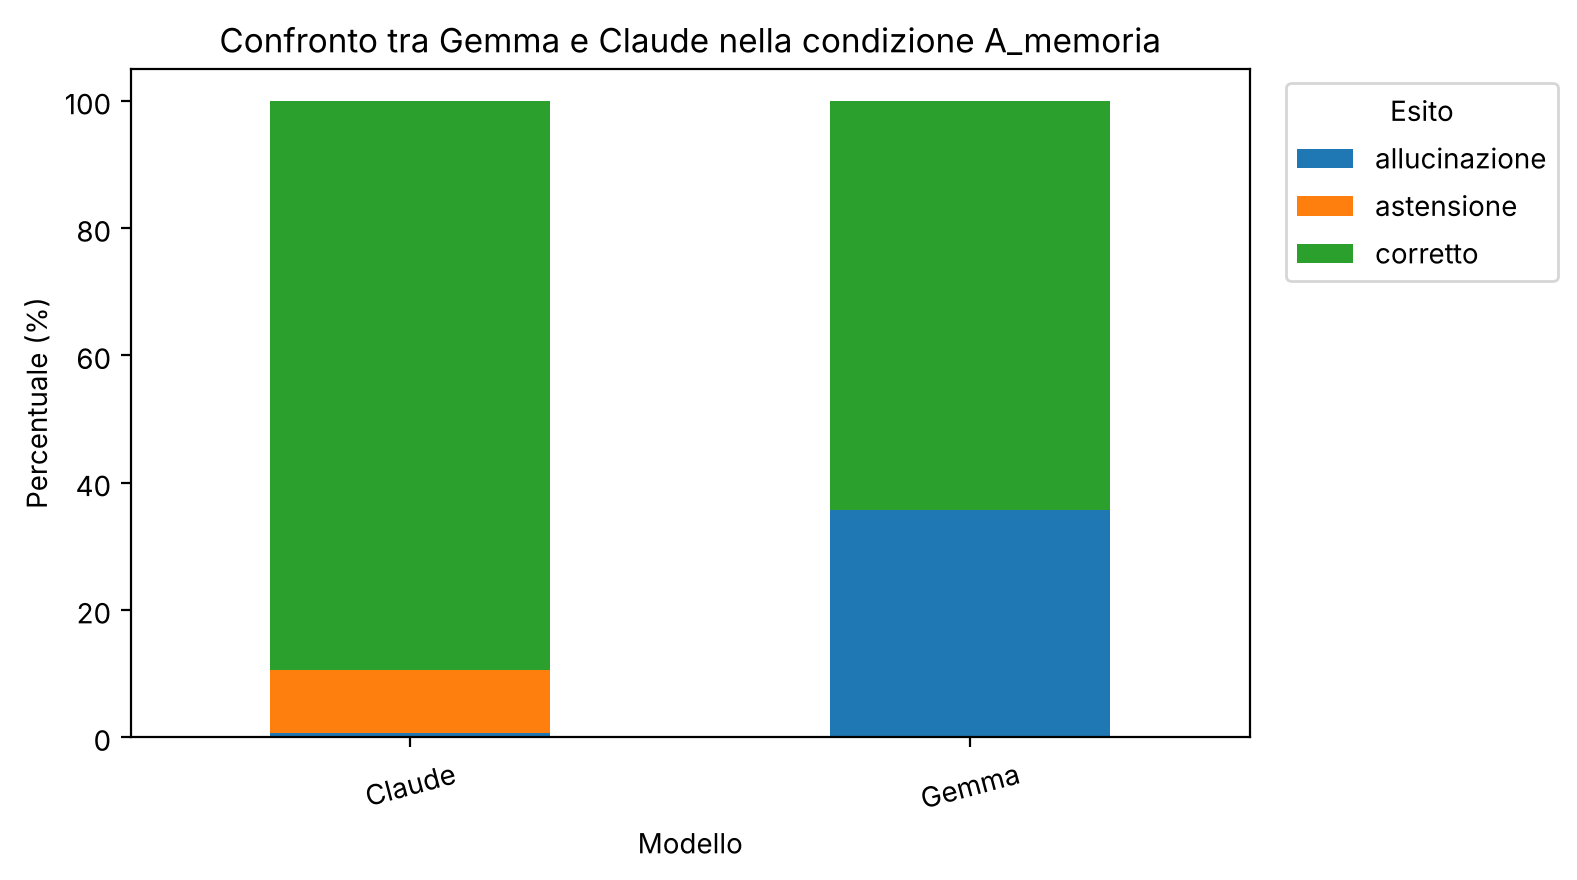

In [ ]:
modelli, modelli_pct = esiti_percentuali(df[df["condizione"] == "A_memoria"], "modello")
display(modelli)
display(modelli_pct)
grafico_impilato(modelli_pct, "Confronto tra Gemma e Claude nella condizione A_memoria", "grafico_2_modelli.png", "Modello")

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<p>Claude inventa <b>una sola volta</b> su 151 (0,7%), Gemma <b>54 volte</b> (35,8%). La differenza sta soprattutto in cosa fanno quando non sanno:
Claude <b>si astiene</b> (10%), Gemma risponde sempre, anche inventando.</p>
</div>

<h2>11. Trabocchetti (RQ1)</h2>
<p><b>Cosa facciamo</b>: dividiamo le risposte di Gemma per tipo di domanda: reali, trabocchetti (premessa falsa) e controlli (stessa informazione senza trucco).</p>
<p><b>Perché</b>: se i trabocchetti vengono sbagliati più delle altre domande, il modello tende ad assecondare la premessa falsa invece di correggerla (RQ1).</p>

esito,allucinazione,astensione,corretto
tipo,,,
controllo,12.22,8.89,78.89
controllo_si,10.00,6.67,83.33
reale,27.98,6.17,65.84
trabocchetto,37.78,11.11,51.11


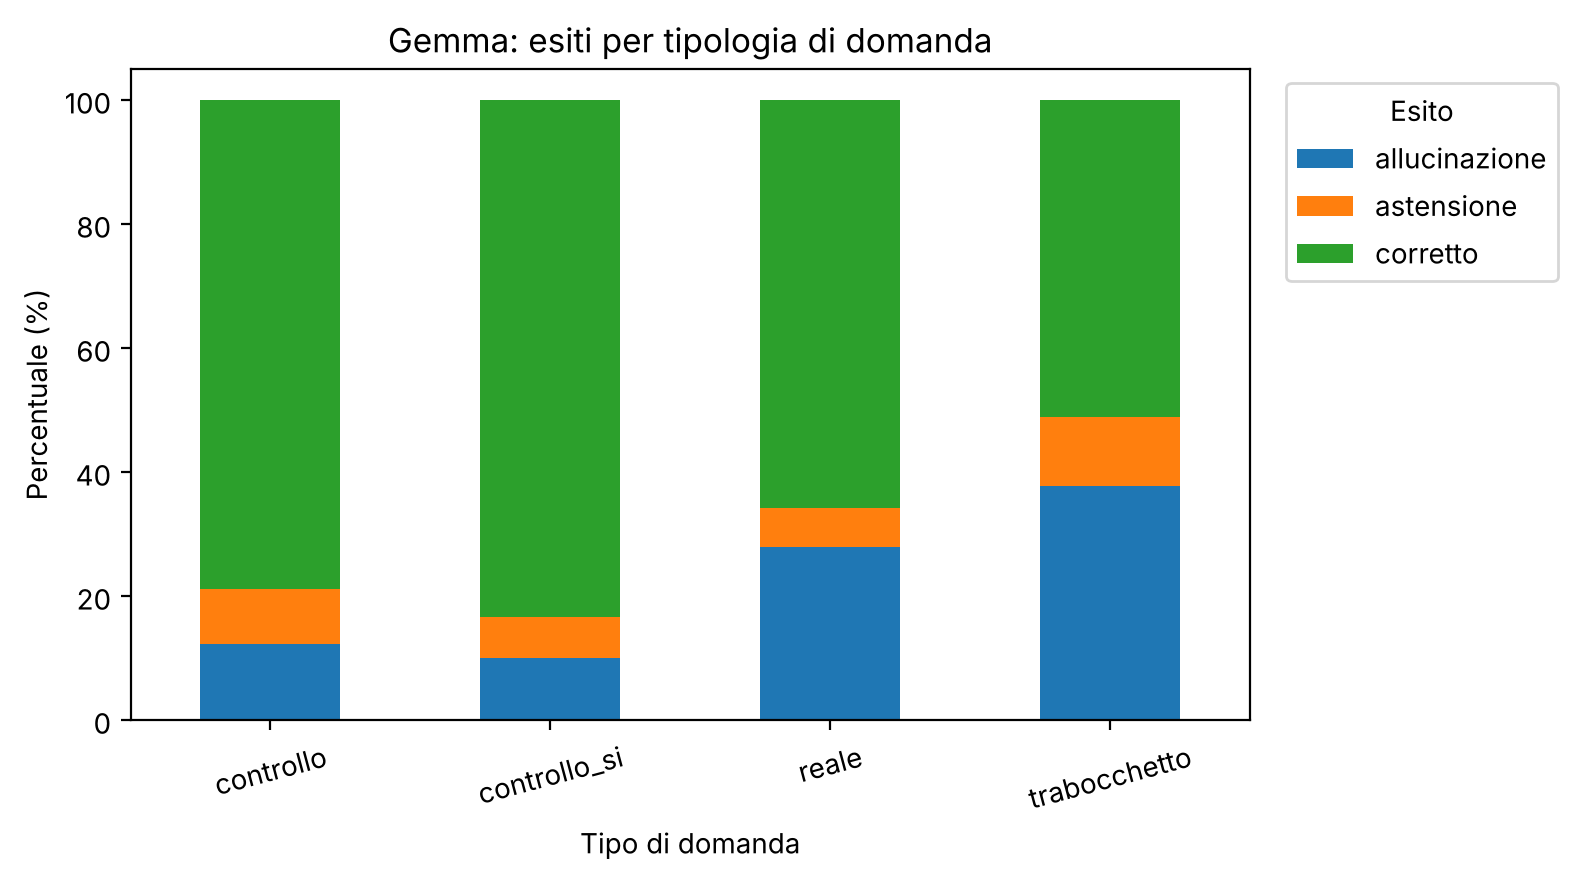

tipo,reale,trabocchetto
condizione,,
A_memoria,40.74,46.67
B_fonti,37.04,63.33
C_corpus,6.17,3.33


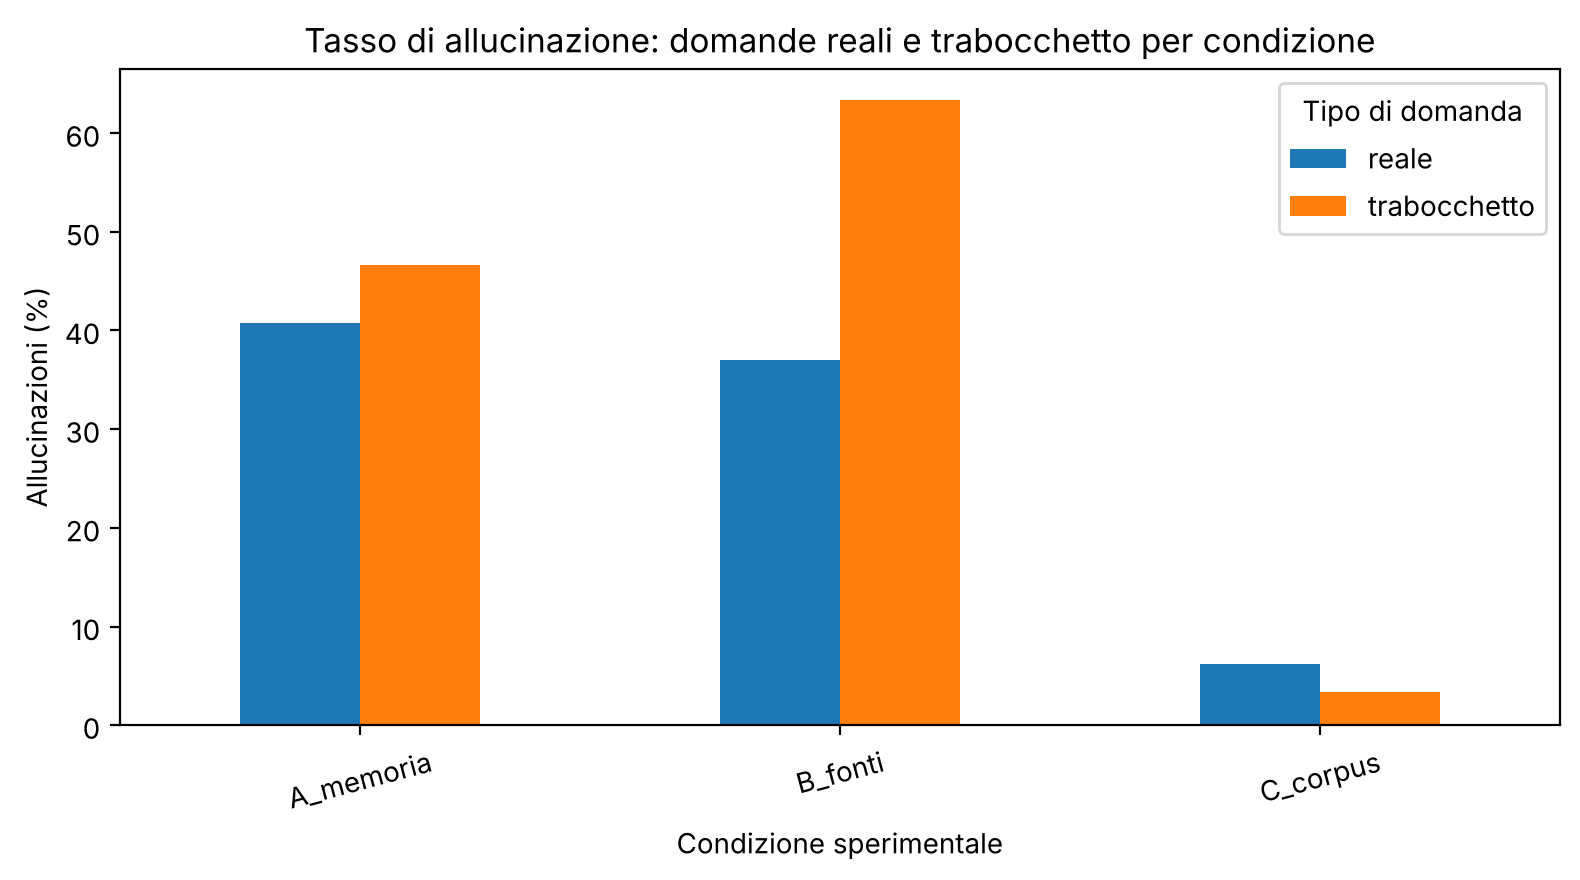

In [ ]:
tipi, tipi_pct = esiti_percentuali(gemma, "tipo")
display(tipi_pct)
grafico_impilato(tipi_pct, "Gemma: esiti per tipologia di domanda", "grafico_3_tipo_domanda.png", "Tipo di domanda")

# Domande reali e trabocchetti a confronto, condizione per condizione
reali_trab = gemma[gemma["tipo"].isin(["reale", "trabocchetto"])]
tasso = (reali_trab["esito"] == "allucinazione").groupby([reali_trab["condizione"], reali_trab["tipo"]]).mean().mul(100).unstack()
display(tasso.round(2))
ax = tasso.plot(kind="bar", figsize=(8, 4.5), title="Tasso di allucinazione: domande reali e trabocchetto per condizione")
ax.set_ylabel("Allucinazioni (%)"); ax.set_xlabel("Condizione sperimentale"); ax.tick_params(axis="x", rotation=15)
ax.legend(title="Tipo di domanda")
plt.tight_layout(); plt.savefig(f"{OUT}/grafico_4_reali_trabocchetti.png", dpi=200); plt.show()

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<p>I trabocchetti sono le domande più insidiose: <b>37,8%</b> di allucinazioni, contro il 28% delle reali e il 12% dei controlli.
Il grafico per condizione mostra che il divario c'è a memoria (47% contro 41%) e soprattutto chiedendo le fonti (<b>63%</b> contro 37%), mentre con gli estratti (C) sparisce (3% contro 6%).
→ <b>RQ1: sì</b>, nelle condizioni A e B.</p>
</div>

<h2>12. Citazioni e fonti (RQ2)</h2>
<p><b>Cosa facciamo</b>: (1) la percentuale di allucinazioni per categoria di domanda; (2) per le citazioni attribuite da Gemma, se il personaggio scelto è coerente con il tono della frase;
(3) nella condizione B, se il capitolo indicato da Gemma è quello giusto.</p>
<p><b>Perché</b>: RQ2 chiede se le citazioni sono la categoria più a rischio e che le invenzioni sono "plausibili". Una fonte inventata rende l'errore ancora più convincente.</p>

,totale,allucinazioni,tasso (%)
categoria,,,
citazioni,112,40,35.71
oggetti,64,18,28.12
personaggi,92,21,22.83
luoghi,76,12,15.79
eventi,72,9,12.50
cronologia,60,6,10.00
relazioni,64,6,9.38
bibliografia,24,2,8.33


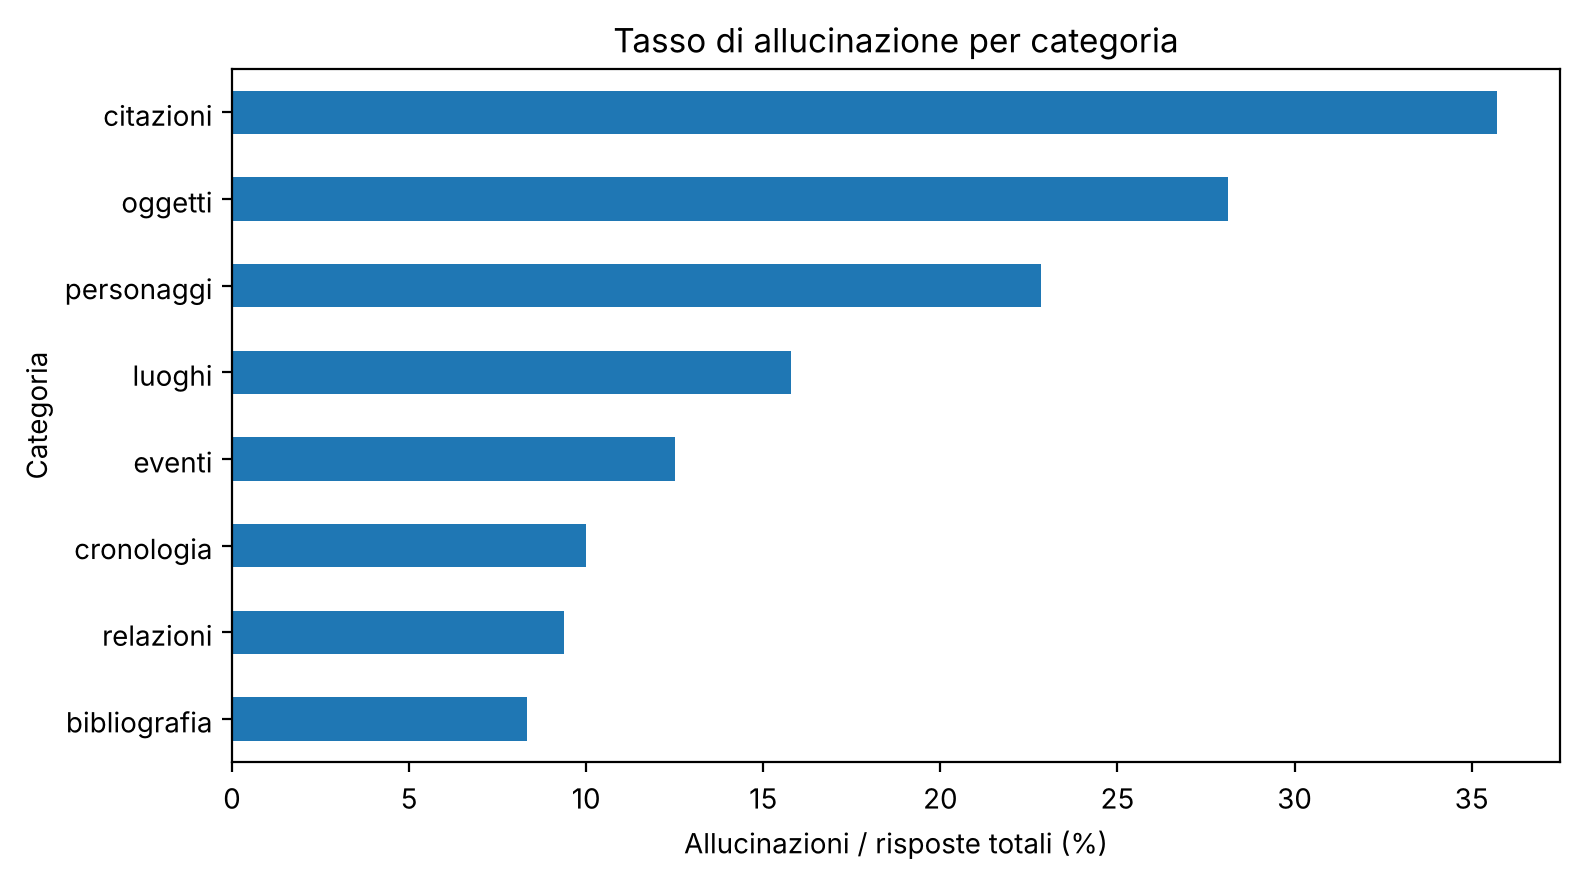

Citazioni attribuite a un personaggio coerente col tono:


coerente_col_tono,no,sì
condizione,,
A_memoria,4,7
B_fonti,5,7


Il capitolo indicato è giusto?


,citazioni,tutte le domande
capitolo_citato_esiste,,
no,20,89
non_indicato,7,21
sì,1,41


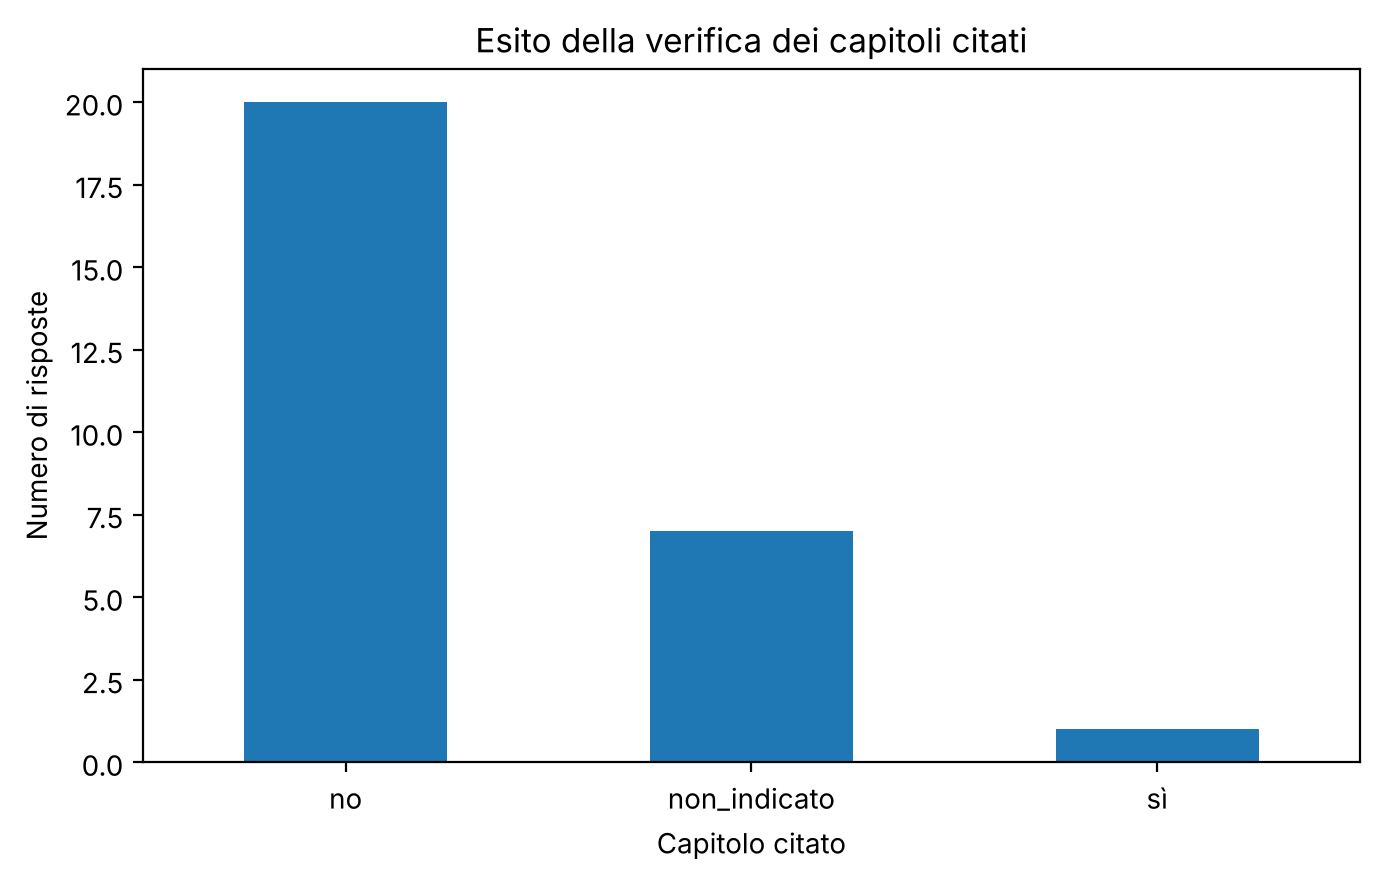

In [ ]:
# 1. Allucinazioni per categoria (controllo_si non è una categoria di contenuto)
dati = df[df["categoria"] != "controllo_si"]
categorie = dati.groupby("categoria")["esito"].agg(totale="size", allucinazioni=lambda x: (x == "allucinazione").sum())
categorie["tasso (%)"] = (categorie["allucinazioni"] / categorie["totale"] * 100).round(2)
categorie = categorie.sort_values("tasso (%)", ascending=False)
display(categorie)
ax = categorie["tasso (%)"].sort_values().plot(kind="barh", figsize=(8, 4.5), title="Tasso di allucinazione per categoria")
ax.set_xlabel("Allucinazioni / risposte totali (%)"); ax.set_ylabel("Categoria")
plt.tight_layout(); plt.savefig(f"{OUT}/grafico_5_categorie.png", dpi=200); plt.show()

# 2. Personaggio coerente con il tono della citazione?
attribuite = gemma[(gemma["categoria"] == "citazioni") & (gemma["coerente_col_tono"].isin(["sì", "no"]))]
print("Citazioni attribuite a un personaggio coerente col tono:")
display(pd.crosstab(attribuite["condizione"], attribuite["coerente_col_tono"]))

# 3. Il capitolo indicato nella condizione B esiste?
fonti = gemma[gemma["condizione"] == "B_fonti"]
capitoli = pd.DataFrame({"citazioni": fonti[fonti["categoria"] == "citazioni"]["capitolo_citato_esiste"].value_counts(),
                         "tutte le domande": fonti["capitolo_citato_esiste"].value_counts()}).fillna(0).astype(int)
print("Il capitolo indicato è giusto?")
display(capitoli)
ax = capitoli["citazioni"].reindex(["no", "non_indicato", "sì"]).plot(kind="bar", figsize=(7, 4.5), title="Esito della verifica dei capitoli citati")
ax.set_xlabel("Capitolo citato"); ax.set_ylabel("Numero di risposte"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(f"{OUT}/grafico_6_capitoli.png", dpi=200); plt.show()

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<ul>
<li>Le <b>citazioni</b> sono la categoria con più allucinazioni (35,7%), seguite da oggetti (28%) e personaggi (23%).</li>
<li>Quando attribuisce una citazione, Gemma sceglie un personaggio coerente con il tono in circa <b>6 casi su 10</b> (es. una frase sulle ombre ad Azriel): l'invenzione è plausibile.</li>
<li>Le fonti <b>sembrano precise ma sono quasi sempre sbagliate</b>: per le 28 citazioni il capitolo è giusto <b>una volta sola</b>; su tutte le domande 41 giusti e 89 sbagliati.</li>
</ul>
<p>→ <b>RQ2: sì</b>. E si capisce perché chiedere le fonti non aiuta (RQ3): Gemma inventa anche quelle.</p>
</div>

<h2>13. Tono e tipi di errore</h2>
<p><b>Cosa facciamo</b>: (1) per ogni tono annotato (sicuro, cauto, incerto) contiamo gli esiti; (2) contiamo i tipi di errore delle 117 allucinazioni.</p>
<p><b>Perché</b>: chi legge si fida di più di una risposta sicura: vediamo se il tono dice qualcosa sulla correttezza. E non tutte le invenzioni sono uguali: inventare da zero è diverso dall'accettare una premessa falsa.</p>

esito,allucinazione,astensione,corretto
tono,,,
cauto,1,2,34
incerto,2,12,1
sicuro,114,36,402


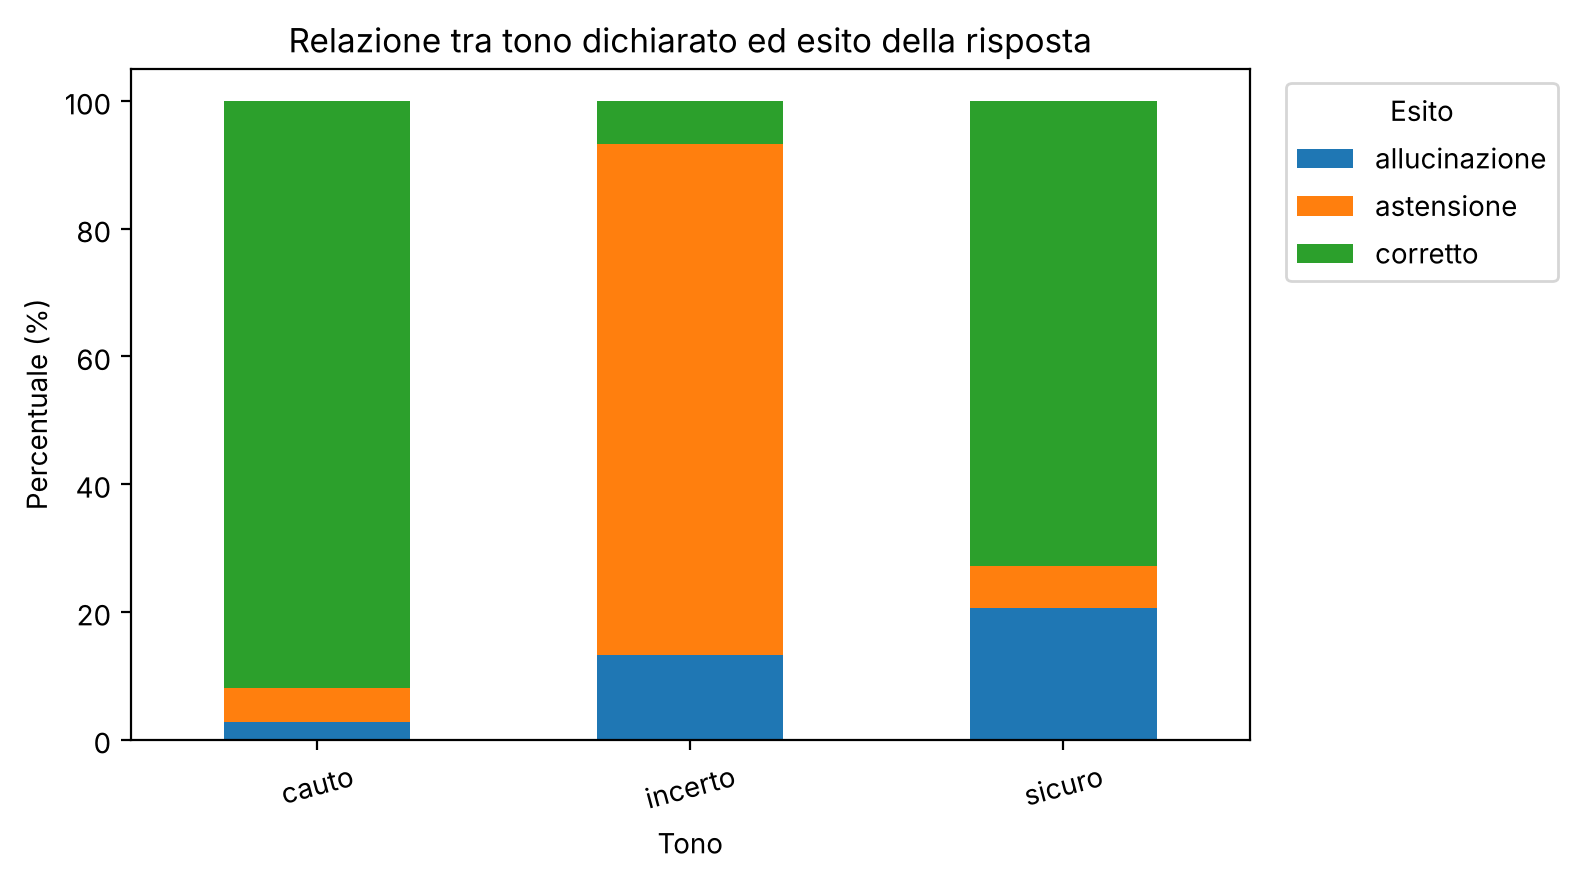

,casi,%
tipo_errore,,
invenzione_integrale,51,43.6
accettazione_premessa,29,24.8
distorsione_parziale,20,17.1
anacronismo,8,6.8
confusione_fonti,7,6.0
fusione_elementi,2,1.7


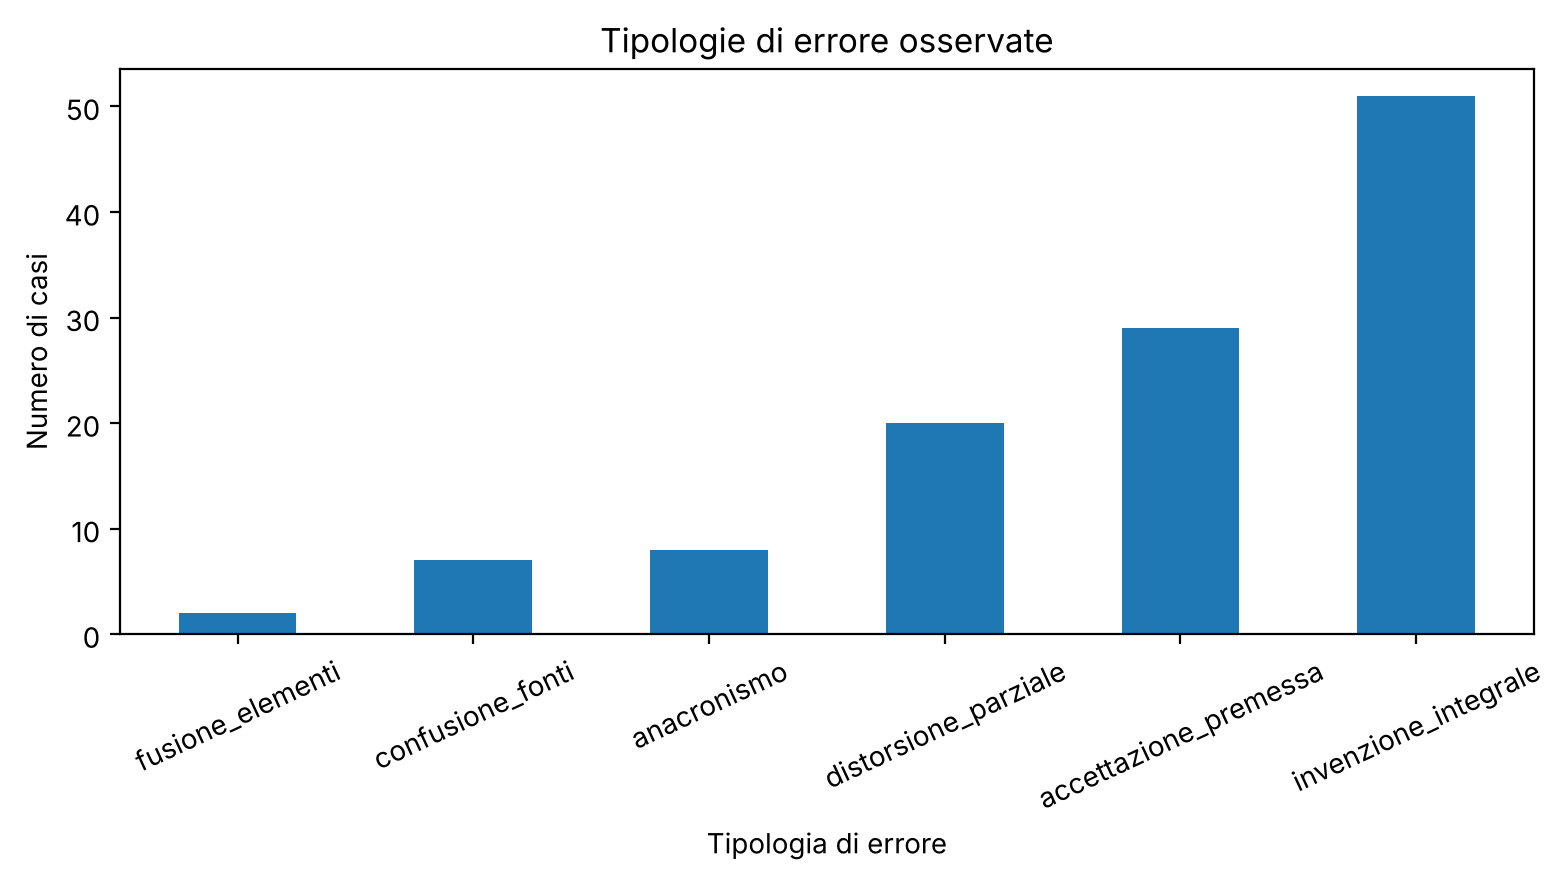

In [ ]:
tono, tono_pct = esiti_percentuali(df, "tono")
display(tono)
grafico_impilato(tono_pct, "Relazione tra tono dichiarato ed esito della risposta", "grafico_7_tono.png", "Tono")

errori = df[df["esito"] == "allucinazione"]
tassonomia = errori["tipo_errore"].value_counts().rename("casi").to_frame()
tassonomia["%"] = (tassonomia["casi"] / len(errori) * 100).round(1)
display(tassonomia)
ax = tassonomia["casi"].sort_values().plot(kind="bar", figsize=(8, 4.5), title="Tipologie di errore osservate")
ax.set_xlabel("Tipologia di errore"); ax.set_ylabel("Numero di casi"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.savefig(f"{OUT}/grafico_8_tipi_errore.png", dpi=200); plt.show()

<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<ul>
<li><b>114 allucinazioni su 117</b> sono scritte con tono sicuro: un'invenzione "suona" come una risposta vera. Il tono incerto compare quasi solo nelle astensioni.</li>
<li>Tipi di errore: <b>invenzione integrale</b> 44% (risposta costruita dal nulla), <b>accettazione della premessa</b> 25% (i trabocchetti), <b>distorsione parziale</b> 17% (fatto vero con un dettaglio sbagliato);
più rari anacronismi, confusione con altre saghe e fusione di elementi.</li>
</ul>
</div>

<h2>14. Le differenze sono reali? (test di McNemar)</h2>
<p><b>Cosa facciamo</b>: confrontiamo le condizioni a due a due <b>sulle stesse domande</b>, guardando solo quelle in cui uno inventa e l'altro no.</p>
<p><b>Perché</b>: con 151 domande una differenza di qualche punto può essere fortuna. Se le domande "vinte" sono divise in modo molto squilibrato (es. 50 contro 2), la differenza è reale; se sono quasi pari (es. 7 contro 9), può essere solo un caso.
Il test lo traduce in un numero, il <b>p-value</b>: sotto 0,05 la differenza è reale.</p>

In [ ]:
from scipy.stats import binomtest

def inventa(modello, condizione):
    dati = df[(df["modello"] == modello) & (df["condizione"] == condizione)]
    return dati.set_index("id")["esito"] == "allucinazione"

righe = []
for nome, primo, secondo in [("Gemma memoria / Claude memoria", inventa("Gemma", "A_memoria"), inventa("Claude", "A_memoria")),
                             ("Gemma memoria / Gemma fonti",    inventa("Gemma", "A_memoria"), inventa("Gemma", "B_fonti")),
                             ("Gemma memoria / Gemma corpus",   inventa("Gemma", "A_memoria"), inventa("Gemma", "C_corpus")),
                             ("Gemma fonti / Gemma corpus",     inventa("Gemma", "B_fonti"),   inventa("Gemma", "C_corpus"))]:
    solo_primo, solo_secondo = (primo & ~secondo).sum(), (~primo & secondo).sum()
    p = binomtest(min(solo_primo, solo_secondo), solo_primo + solo_secondo, 0.5).pvalue
    righe.append({"confronto": nome, "inventa solo il 1°": solo_primo, "inventa solo il 2°": solo_secondo,
                  "p-value": "meno di 0,001" if p < 0.001 else f"{p:.2f}".replace(".", ","),
                  "differenza reale": "sì" if p < 0.05 else "no"})
mcnemar = pd.DataFrame(righe)
display(mcnemar)

,confronto,inventa solo il 1°,inventa solo il 2°,p-value,differenza reale
0,Gemma memoria / Claude memoria,53,0,"meno di 0,001",sì
1,Gemma memoria / Gemma fonti,7,9,"0,80",no
2,Gemma memoria / Gemma corpus,50,2,"meno di 0,001",sì
3,Gemma fonti / Gemma corpus,53,3,"meno di 0,001",sì


<div style="border-left:4px solid #1baf7a;background:rgba(27,175,122,.08);padding:8px 14px">
<b>Cosa emerge</b>
<ul>
<li><b>Gemma contro Claude</b>: 53 domande in cui inventa solo Gemma, 0 solo Claude → differenza reale.</li>
<li><b>Memoria contro fonti</b>: 7 contro 9, quasi pari (p = 0,80) → nessuna differenza (RQ3: no).</li>
<li><b>Memoria o fonti contro corpus</b>: 50 contro 2 e 53 contro 3 → gli estratti riducono davvero le invenzioni (RQ4: sì).</li>
</ul>
</div>

<h2>15. Esempi di risposte</h2>
<p><b>Cosa facciamo</b>: mostriamo alcune domande con la risposta giusta e le risposte dei modelli, con l'esito annotato.</p>
<p><b>Perché</b>: i numeri dicono quanto spesso il modello inventa; gli esempi mostrano <b>come</b>.</p>

In [ ]:
ESEMPI = {
    "P13":  "Trabocchetto (RQ1): Feyre non ha fratelli, ma Gemma gli inventa un nome. Claude corregge la premessa.",
    "Q17":  "Citazione inventata da noi (RQ2): Gemma la attribuisce ad Azriel, il personaggio legato alle ombre.",
    "Q06":  "Citazione (RQ2): Gemma inventa la prima frase del primo libro, con sicurezza.",
    "P14":  "Fonti (RQ3): chiedendo le fonti Gemma inventa una sorella di Amarantha e la sua storia, citando un libro.",
    "P01":  "Fonti (RQ3): risposta giusta, ma con le fonti Gemma inventa il titolo del libro.",
    "O10c": "Le Wyrdkey sono di un'altra saga della stessa autrice: Gemma le mette in ACOWAR con dettagli inventati.",
}
for qid, perche in ESEMPI.items():
    righe = df[df["id"] == qid]
    print(f"{qid} – {righe['domanda'].iloc[0]}\n  Risposta giusta: {righe['risposta_riferimento'].iloc[0]}")
    for r in righe.itertuples():
        testo = " ".join(str(r.risposta_modello).split())
        print(f"  {r.modello} {r.condizione} – {r.esito.upper()}: {testo[:200]}{'…' if len(testo) > 200 else ''}")
    print(f"  Perché è interessante: {perche}\n")

P13 – Come si chiama il fratello minore di Feyre?
  Risposta giusta: Premessa falsa: Feyre non ha un fratello minore; ha due sorelle maggiori, Nesta ed Elain.
  Gemma A_memoria – ALLUCINAZIONE: Il fratello minore di Feyre si chiama Henry.
  Gemma B_fonti – ALLUCINAZIONE: Il fratello minore di Feyre si chiama Henry. **Fonte:** *Un cortile di rose e spine*, Capitolo 1.
  Gemma C_corpus – ASTENSIONE: Gli estratti forniti non contengono la risposta a questa domanda.
  Claude A_memoria – CORRETTO: Feyre non ha un fratello minore. Nella saga di Sarah J. Maas, Feyre Archeron è la più giovane di tre sorelle: le maggiori sono Nesta ed Elain. La famiglia comprende anche il padre, un mercante caduto …
  Perché è interessante: Trabocchetto (RQ1): Feyre non ha fratelli, ma Gemma gli inventa un nome. Claude corregge la premessa.

Q17 – Chi pronuncia la frase «Nelle ombre non c'è paura, solo pazienza» e in quale libro?
  Risposta giusta: Citazione inventata: la frase non compare nella saga.
  Gemma A

<h2>16. Riepilogo e salvataggio</h2>
<p><b>Cosa facciamo</b>: una tabella finale con i numeri principali, poi salviamo tutte le tabelle in un Excel e tutto (Excel e grafici) in un file ZIP.</p>

In [ ]:
gruppi = {"Gemma - A memoria": gemma[gemma["condizione"] == "A_memoria"], "Gemma - B fonti": gemma[gemma["condizione"] == "B_fonti"],
          "Gemma - C corpus": gemma[gemma["condizione"] == "C_corpus"], "Claude - A memoria": df[df["modello"] == "Claude"]}
riepilogo = pd.DataFrame({nome: {"risposte": len(d),
                                 "corrette (%)": (d["esito"] == "corretto").mean() * 100,
                                 "allucinazioni (%)": (d["esito"] == "allucinazione").mean() * 100,
                                 "astensioni (%)": (d["esito"] == "astensione").mean() * 100}
                          for nome, d in gruppi.items()}).T.round(2)
riepilogo["risposte"] = riepilogo["risposte"].astype(int)
display(riepilogo)

with pd.ExcelWriter(f"{OUT}/ACOTAR_risultati.xlsx") as excel:
    for nome, tabella in {"riepilogo": riepilogo, "condizioni": condizioni, "gemma_claude": modelli, "tipo_domanda": tipi,
                          "categorie": categorie, "capitoli": capitoli, "tono": tono, "tipi_errore": tassonomia}.items():
        tabella.to_excel(excel, sheet_name=nome)
    mcnemar.to_excel(excel, sheet_name="mcnemar", index=False)
    if "tabella" in globals():                      # tabella del test di familiarità, se è stata eseguita
        tabella.to_excel(excel, sheet_name="familiarita", index=False)

with zipfile.ZipFile(f"{OUT}/ACOTAR_risultati.zip", "w") as archivio:
    for nome_file in sorted(os.listdir(OUT)):
        if nome_file == "ACOTAR_risultati.xlsx" or re.match(r"grafico_\d", nome_file):
            archivio.write(f"{OUT}/{nome_file}", arcname=nome_file)
print("Analisi completata. File salvati in 06_risultati.")

,risposte,corrette (%),allucinazioni (%),astensioni (%)
Gemma - A memoria,151,64.24,35.76,0.00
Gemma - B fonti,151,62.91,37.09,0.00
Gemma - C corpus,151,72.85,3.97,23.18
Claude - A memoria,151,89.40,0.66,9.93


Analisi completata. File salvati in 06_risultati.


<h2>Conclusioni</h2>
<p><b>Quanto spesso un'IA inventa informazioni su un universo narrativo?</b> Dipende dal modello e da cosa gli diamo:
Gemma a memoria inventa in <b>circa 1 risposta su 3</b>, Claude quasi mai; con gli estratti dei libri Gemma scende al 4%.</p>
<table>
<tr><th></th><th>Domanda di ricerca</th><th>Risposta</th></tr>
<tr><td><b>RQ1</b></td><td>Trabocchetti</td><td><b>Sì</b>: le domande con più invenzioni (38%), 63% quando chiediamo le fonti.</td></tr>
<tr><td><b>RQ2</b></td><td>Citazioni</td><td><b>Sì</b>: la categoria più critica, spesso attribuite a un personaggio coerente col tono.</td></tr>
<tr><td><b>RQ3</b></td><td>Chiedere le fonti</td><td><b>No</b>: le invenzioni non diminuiscono e i capitoli indicati sono quasi sempre sbagliati.</td></tr>
<tr><td><b>RQ4</b></td><td>Dare gli estratti dei libri</td><td><b>Sì</b>: allucinazioni dal 36% al 4%.</td></tr>
</table>
<p>Inoltre: quasi tutte le invenzioni hanno tono sicuro, e il test di familiarità mostra che Gemma non conosce i libri mentre Claude li conosce molto meglio e, quando non è sicuro, lo dice.</p>
<p><b>Limiti</b>: un solo annotatore; 151 domande su una sola saga; Claude testato solo a memoria.</p>